In [3]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt('https://lectures.scientific-python.org/_downloads/087d8fe936fcb7a4762b9850b932cf9e/populations.txt')

years, hares, lynxes, carrots = data.T

Matplotlib is building the font cache; this may take a moment.


Plot the population size of each species for each year on a single graph. Add legend and axis labels to the plot.

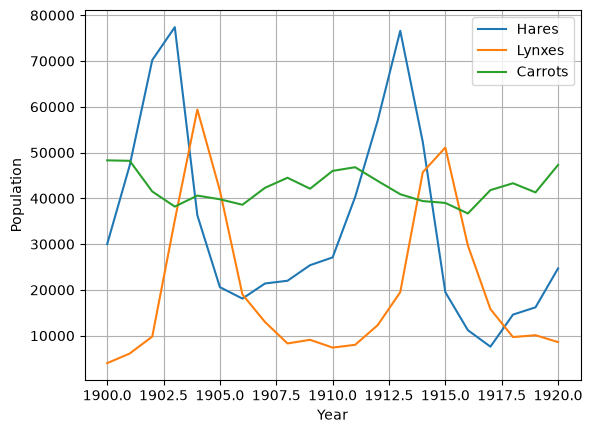

In [4]:
plt.plot(years, hares, label='Hares')
plt.plot(years, lynxes, label='Lynxes')
plt.plot(years, carrots, label='Carrots')

plt.xlabel('Year')
plt.ylabel('Population')
plt.legend()
plt.grid()
plt.show()

Find which year each species had the largest population. Mark these years in the plot of populations.

Years of maximum: [1903. 1904. 1900.]


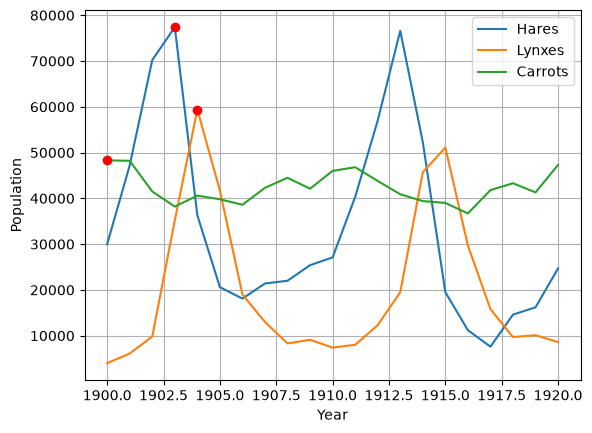

In [5]:
imax = data[:, 1:].argmax(axis=0)
print('Years of maximum:', years[imax])

plt.plot(years, data[:, 1:])
plt.scatter(years[imax], data[imax, np.arange(1, 4)], color='red', zorder=3)
plt.xlabel('Year')
plt.ylabel('Population')
plt.legend(['Hares', 'Lynxes', 'Carrots'])
plt.grid()
plt.show()

ssuming total population of hares and lynxes is 100%, plot stacked bar graph showing ratio of each specis for each year in the period.

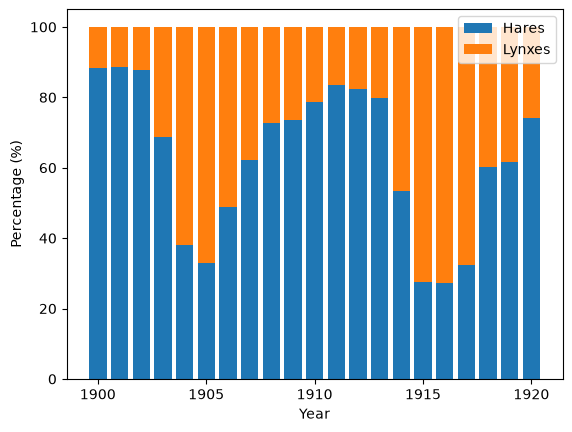

In [6]:
h = hares / (hares + lynxes) * 100
l = lynxes / (hares + lynxes) * 100

plt.bar(years, h, label='Hares')
plt.bar(years, l, bottom=h, label='Lynxes')

plt.xlabel('Year')
plt.ylabel('Percentage (%)')
plt.legend()
plt.show()

Find the mean and std of the populations of each species. Plot the historgam of population for each species and show mean values with vertical line. Show each histogram in a separate plot. Arrange 3 plots in a row.

Mean: [34080.95238095 20166.66666667 42400.        ]
Std: [20897.90645809 16254.59153691  3322.50622558]


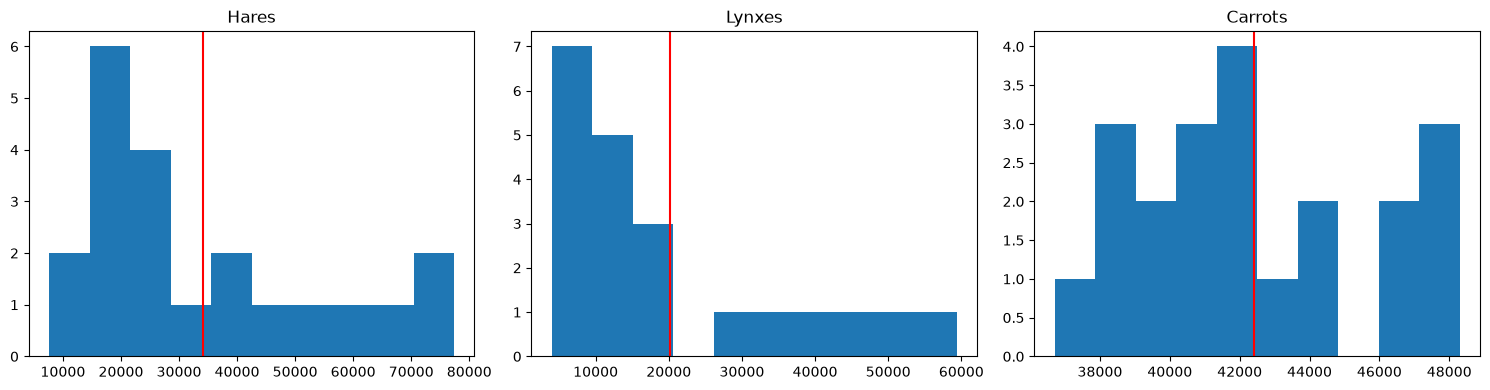

In [8]:
print('Mean:', data[:, 1:].mean(axis=0))
print('Std:', data[:, 1:].std(axis=0))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].hist(hares)
ax[0].axvline(hares.mean(), color='red')
ax[0].set_title('Hares')

ax[1].hist(lynxes)
ax[1].axvline(lynxes.mean(), color='red')
ax[1].set_title('Lynxes')

ax[2].hist(carrots)
ax[2].axvline(carrots.mean(), color='red')
ax[2].set_title('Carrots')

plt.tight_layout()
plt.show()

Find which species (hares or lynxes) has the largest population for each year. Print the result as [H, H, L, H, ...]. Plot a pie chart showing the ratio of "H" and "L" values.

['H' 'H' 'H' 'H' 'L' 'L' 'L' 'H' 'H' 'H' 'H' 'H' 'H' 'H' 'H' 'L' 'L' 'L'
 'H' 'H' 'H']


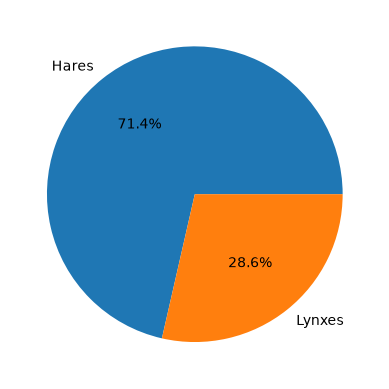

In [9]:
result = np.where(hares >= lynxes, 'H', 'L')
print(result)

counts = np.array([np.sum(result == 'H'), np.sum(result == 'L')])

plt.pie(counts, labels=['Hares', 'Lynxes'], autopct='%1.1f%%')
plt.show()

Plot the change in the hare population and in the lynx population for each year. Find the correlation coefficient between the both time series.

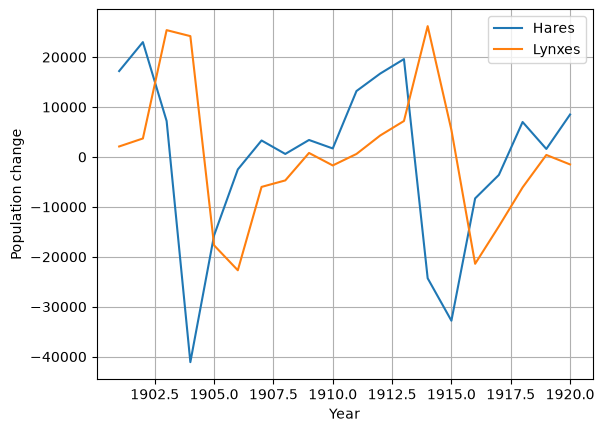

Correlation: -0.1780136594118296


In [10]:
dh = np.diff(hares)
dl = np.diff(lynxes)

plt.plot(years[1:], dh, label='Hares')
plt.plot(years[1:], dl, label='Lynxes')

plt.xlabel('Year')
plt.ylabel('Population change')
plt.legend()
plt.grid()
plt.show()

print('Correlation:', np.corrcoef(dh, dl)[0, 1])

Using a scatter plot, show the population of hares vs lynxes by year (each point corresponds to a particular year, and the point coordinates correspond to the population of the two species in that year).

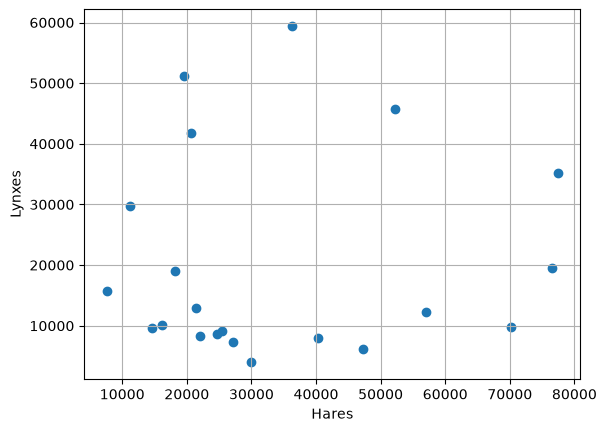

In [11]:
plt.scatter(hares, lynxes)

plt.xlabel('Hares')
plt.ylabel('Lynxes')
plt.grid()
plt.show()

Assume the population of hares in 1920 is unknown. Suggest a way to estimate this value. Compare an estimated value with the true value and print a ratio of the error to the true value.

In [12]:
estimate = 2 * hares[-2] - hares[-3]
error = abs(estimate - hares[-1]) / hares[-1]

print('Estimated:', estimate)
print('True:', hares[-1])
print('Relative error:', error)

Estimated: 17800.0
True: 24700.0
Relative error: 0.2793522267206478


k-means

In [13]:
from sklearn.datasets import fetch_openml
from scipy.optimize import linear_sum_assignment

In [16]:
def k_means(X, k, max_iter=100, threshold=1e-4):
    X = np.asarray(X, dtype=np.float64)
    n, m = X.shape

    if not 1 <= k <= n:
        raise ValueError("k должно быть от 1 до числа объектов")
    if max_iter < 1 or threshold < 0:
        raise ValueError("Некорректные max_iter или threshold")

    rng = np.random.default_rng(42)
    centers = X[rng.choice(n, k, replace=False)].copy()
    prev_error = np.inf

    for _ in range(max_iter):
        distances = (
            np.sum(X**2, axis=1)[:, None]
            - 2 * X @ centers.T
            + np.sum(centers**2, axis=1)
        )

        labels = np.argmin(distances, axis=1)

        counts = np.bincount(labels, minlength=k)
        new_centers = np.zeros((k, m))

        np.add.at(new_centers, labels, X)

        nonempty = counts > 0
        new_centers[nonempty] /= counts[nonempty, None]
        new_centers[~nonempty] = centers[~nonempty]

        centers = new_centers

        error = np.sum((X - centers[labels])**2)

        if abs(prev_error - error) < threshold:
            break

        prev_error = error

    distances = (
        np.sum(X**2, axis=1)[:, None]
        - 2 * X @ centers.T
        + np.sum(centers**2, axis=1)
    )

    labels = np.argmin(distances, axis=1)
    error = np.sum((X - centers[labels])**2)

    return labels, error

In [19]:
from sklearn.datasets import fetch_openml

images, labels = fetch_openml(
    'mnist_784',
    version=1,
    return_X_y=True,
    as_frame=False,
    parser='liac-arff'
)

images = images.astype(float) / 255
labels = labels.astype(int)

print(images.shape)
print(labels.shape)

(70000, 784)
(70000,)


In [20]:
clusters, error = k_means(
    images,
    k=10,
    max_iter=100,
    threshold=1e-4
)

print('Sum of squared errors:', error)
print('Cluster sizes:', np.bincount(clusters, minlength=10))

Sum of squared errors: 2744525.68046581
Cluster sizes: [7840 8463 6364 6210 6257 8265 9069 5437 5872 6223]


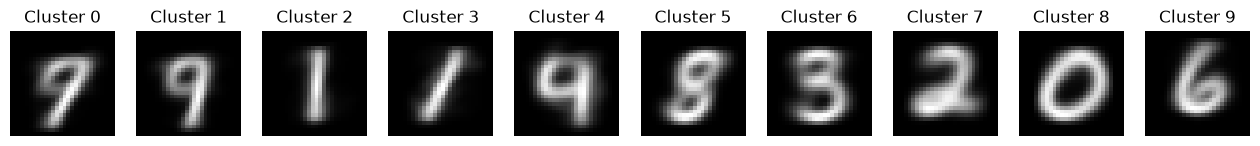

In [21]:
centers = np.zeros((10, 784))
np.add.at(centers, clusters, images)

counts = np.bincount(clusters, minlength=10)
nonempty = counts > 0
centers[nonempty] /= counts[nonempty, None]

fig, ax = plt.subplots(1, 10, figsize=(16, 3))

for i in range(10):
    ax[i].imshow(centers[i].reshape(28, 28), cmap='gray')
    ax[i].set_title(f'Cluster {i}')
    ax[i].axis('off')

plt.show()

In [22]:
counts_table = np.zeros((10, 10), dtype=int)

np.add.at(counts_table, (clusters, labels), 1)

print(counts_table)

[[  35    7   75   45 1791  351    1 3301  267 1967]
 [  15    9   44  179 1913  342    4 2766  241 2950]
 [   0 4371  368  414  112  133  279  246  293  148]
 [  36 3449  469   98  271  825  229  289  456   88]
 [  99    3  261   72 2554  216  665  626  156 1605]
 [ 619    7  163 1390   11 2152  163    4 3700   56]
 [ 286   11  450 4577    0 2051   35    3 1565   91]
 [  45    9 4906  262   18   21   83   40   48    5]
 [5507    0   75   37    4   70   90   14   36   39]
 [ 261   11  179   67  150  152 5327    4   63    9]]


In [23]:
rows, cols = linear_sum_assignment(-counts_table)

digit_for_cluster = np.zeros(10, dtype=int)
digit_for_cluster[rows] = cols

print('Digit for each cluster:', digit_for_cluster)

Digit for each cluster: [7 9 1 5 4 8 3 2 0 6]


In [24]:
correct = counts_table[np.arange(10), digit_for_cluster]

print('Correct images in each cluster:', correct)
print('Total correct:', correct.sum())
print('Accuracy:', correct.sum() / len(labels))

Correct images in each cluster: [3301 2950 4371  825 2554 3700 4577 4906 5507 5327]
Total correct: 38018
Accuracy: 0.5431142857142857


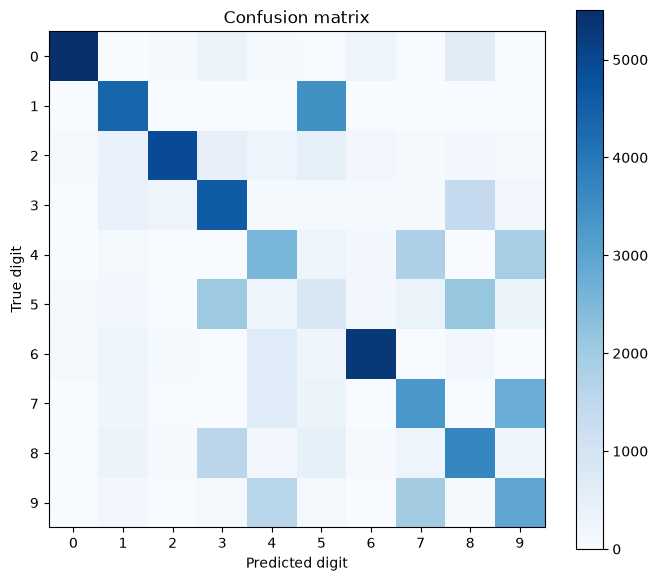

In [25]:
predicted = digit_for_cluster[clusters]

confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (labels, predicted), 1)

plt.figure(figsize=(8, 7))
plt.imshow(confusion, cmap='Blues')
plt.colorbar()

plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel('Predicted digit')
plt.ylabel('True digit')
plt.title('Confusion matrix')

plt.show()